### In this notebook I tried a different approach with combining the datasets and did some EDA with the whole set

In [19]:
# IMPORTS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [20]:
# Combining the datasets together with a new column for run_id and road_id

dfA1 = pd.read_csv("../dataset/cleaned/Iisingintie0.csv")
dfA2 = pd.read_csv("../dataset/cleaned/Iisingintie1.csv")
dfA3 = pd.read_csv("../dataset/cleaned/Iisingintie2.csv")

dfB1 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie0.csv")
dfB2 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie1.csv")
dfB3 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie2.csv")
dfB4 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie3.csv")

dfC1 = pd.read_csv("../dataset/cleaned/Kaittiaisentie0.csv")


runs = {
    "A1": (dfA1, "A"), "A2": (dfA2, "A"), "A3": (dfA3, "A"),
    "B1": (dfB1, "B"), "B2": (dfB2, "B"), "B3": (dfB3, "B"), "B4": (dfB4, "B"),
    "C1": (dfC1, "C"),
}

df = pd.concat(
    [d.assign(run_id=rid, road_id=road) for rid, (d, road) in runs.items()],
    ignore_index=True,
)

In [ ]:
df["AccMagnitude"] = np.sqrt(
    df["AccX"]**2 +
    df["AccY"]**2 +
    df["AccZ"]**2
)

df["GyrMagnitude"] = np.sqrt(
    df["GyrX"]**2 +
    df["GyrY"]**2 +
    df["GyrZ"]**2
)



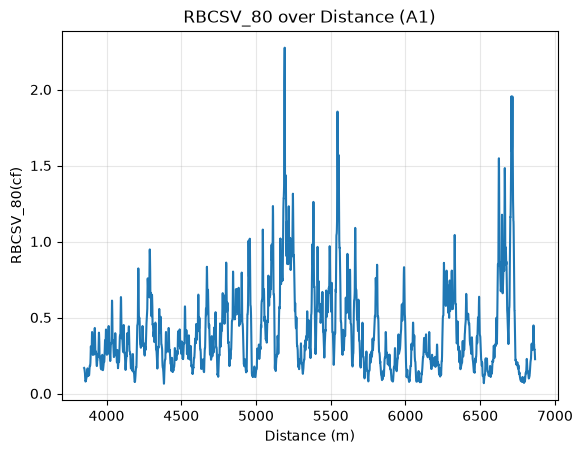

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.lineplot(
    data=df[df["run_id"] == "A1"],
    x="Loc(m)",
    y="RBCSV_80(cf)"
)

plt.title("RBCSV_80 over Distance (A1)")
plt.xlabel("Distance (m)")
plt.ylabel("RBCSV_80(cf)")
plt.grid(alpha=0.3)
plt.show()

In [21]:
df

,Timer(ms),Loc(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,AccY,AccZ,GyrX,GyrY,GyrZ,RBCSV_80(cf),Speed_kmh,Frostbumps,run_id,road_id
0,45493158.5,3850.503,106.794,1.1747,-3.0780,141.0204,1.53481,0.05712,9.58495,0.03196,0.00072,-0.00300,0.16845,62.1936,0,A1,A
1,45493161.0,3850.546,106.794,1.2245,-3.0428,141.1350,1.51066,-0.04196,10.50449,0.02201,0.00598,-0.01390,0.16846,62.2044,0,A1,A
2,45493163.5,3850.589,106.794,1.2281,-3.0428,141.1349,1.15831,0.37071,10.76888,0.01993,0.00065,-0.00562,0.16846,62.2116,0,A1,A
3,45493166.0,3850.633,106.794,1.2330,-3.0430,141.1341,1.03301,0.31102,11.42271,0.02887,-0.00077,-0.01012,0.16845,62.2224,0,A1,A
4,45493168.5,3850.676,106.794,1.2363,-3.0431,141.1329,0.99574,-0.37334,11.76243,0.01783,0.00007,-0.01306,0.16843,62.2332,0,A1,A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
396931,48391434.5,3157.848,120.738,0.6624,-3.4168,-47.3993,-0.40183,0.28938,9.78850,-0.02246,0.01337,-0.00194,0.42374,32.9796,0,C1,C
396932,48391437.0,3157.871,120.738,0.6598,-3.4154,-47.3987,-0.42412,0.19784,9.78453,-0.02360,0.01054,-0.00004,0.42612,32.9760,0,C1,C
396933,48391439.5,3157.894,120.739,0.6575,-3.4144,-47.3981,-0.38394,0.20489,9.77121,-0.02072,0.00785,-0.00054,0.42740,32.9724,0,C1,C
396934,48391442.0,3157.917,120.739,0.6554,-3.4136,-47.3982,-0.32756,0.11798,9.63872,-0.02030,0.00637,-0.00511,0.42867,32.9652,0,C1,C


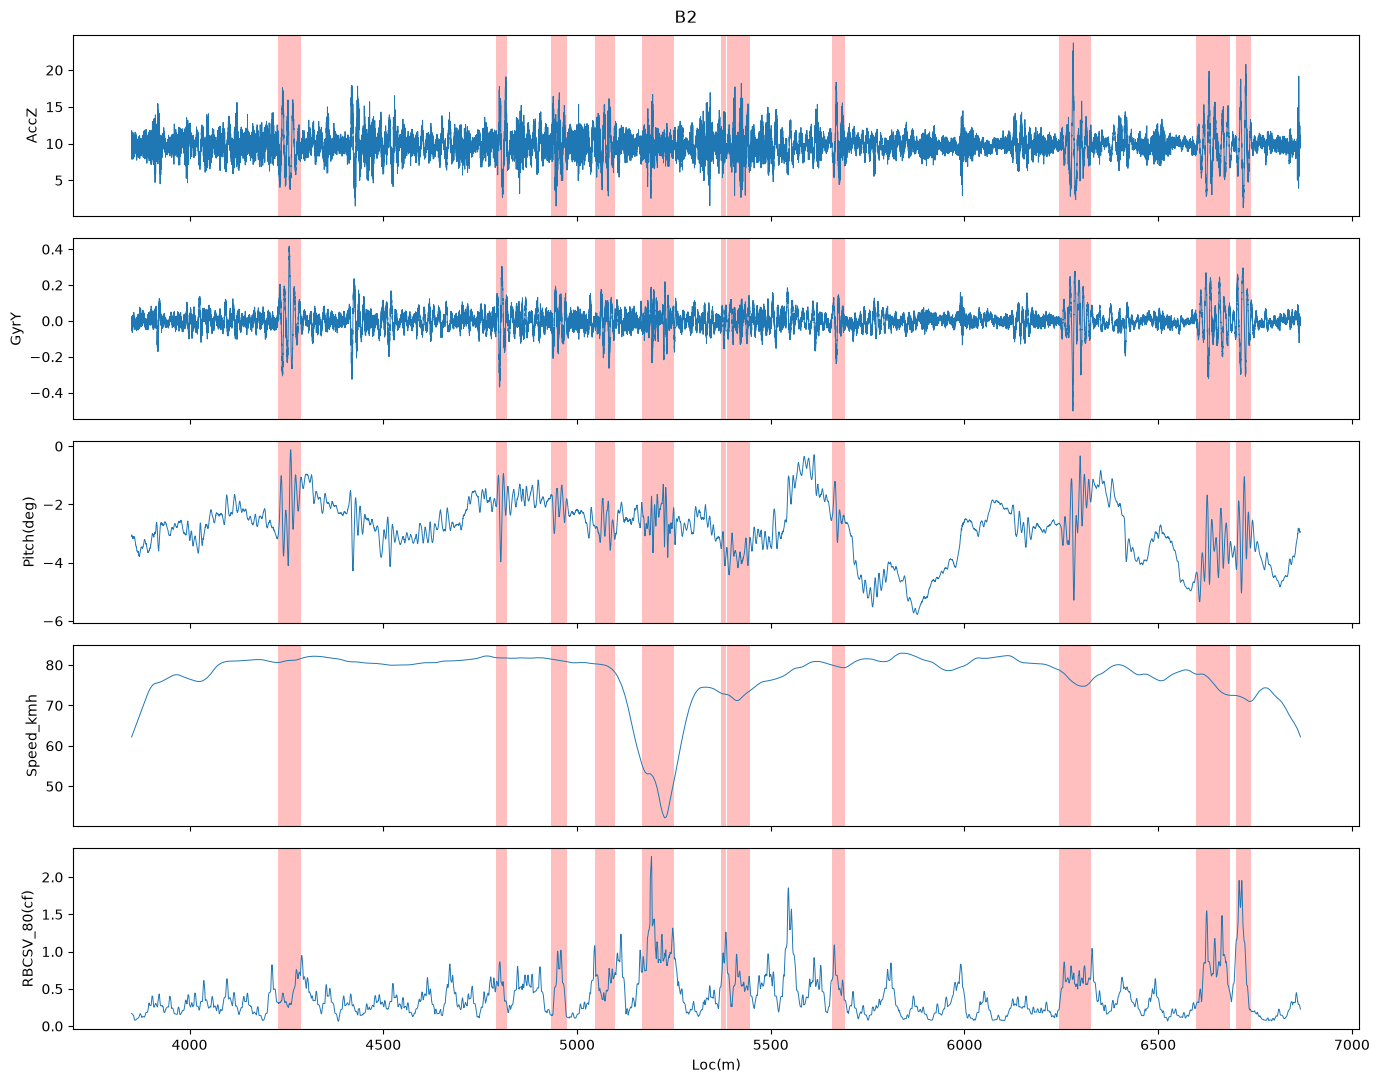

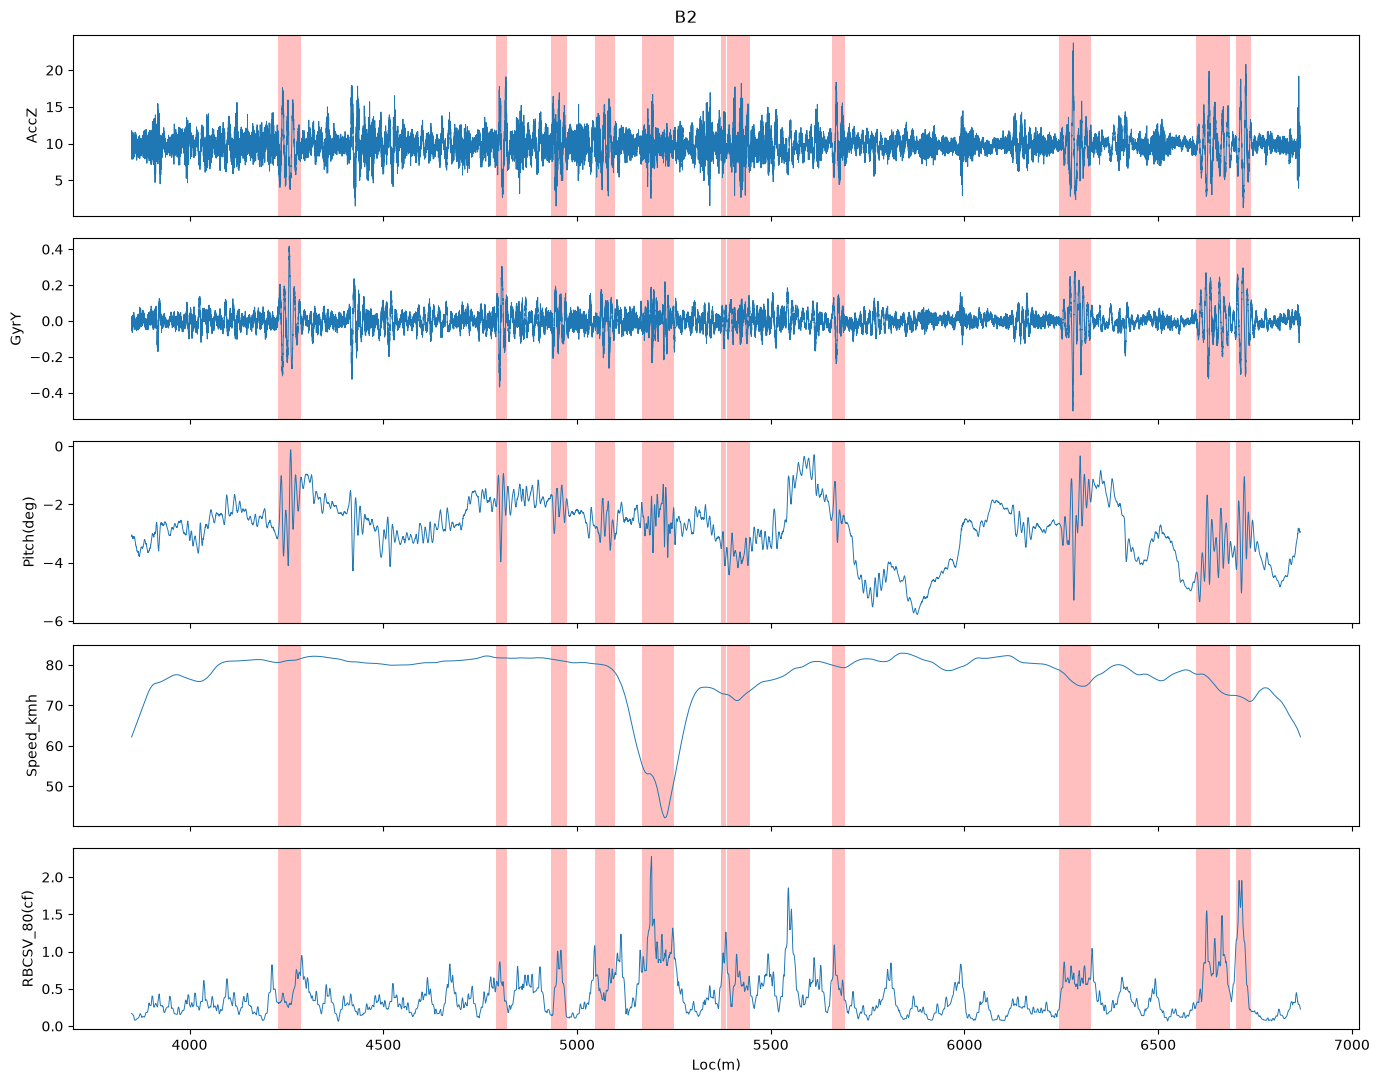

In [42]:


def plot_run(d, feats=("AccZ", "GyrY", "Pitch(deg)", "Speed_kmh", "RBCSV_80(cf)"),
             x="Loc(m)", title=None, xlim=None):
    fig, axes = plt.subplots(len(feats), 1, figsize=(14, 2.2 * len(feats)),
                             sharex=True)
    for ax, f in zip(axes, feats):
        ax.plot(d[x], d[f], lw=0.7)
        ax.set_ylabel(f)

        # shade flagged bump regions
        flag = d["Frostbumps"].to_numpy() == 1
        edges = np.diff(flag.astype(int), prepend=0, append=0)
        starts, ends = np.where(edges == 1)[0], np.where(edges == -1)[0] - 1
        for s, e in zip(starts, ends):
            ax.axvspan(d[x].iloc[s], d[x].iloc[e], color="red", alpha=0.25, lw=0)

    axes[-1].set_xlabel(x)
    if xlim: axes[-1].set_xlim(xlim)
    fig.suptitle(title or "")
    fig.tight_layout()
    return fig

import numpy as np
plot_run(df[df.run_id == "A1"], title="B2")

In [23]:
# Check the distribution of labels
print(df["Frostbumps"].value_counts())

# Percentage of positive rows per run
print(
    df.groupby("run_id")["Frostbumps"]
      .mean()
      .mul(100)
)

Frostbumps
0    326779
1     70157
Name: count, dtype: int64
run_id
A1    20.540503
A2    19.818459
A3    18.410589
B1    56.411453
B2    42.113503
B3    44.643244
B4    33.864740
C1     4.882321
Name: Frostbumps, dtype: float64


In [24]:
df_sorted = df.sort_values(
    ["run_id", "Timer(ms)"]
).copy()

# Identify consecutive groups of identical labels
df_sorted["segment"] = (
    df_sorted.groupby("run_id")["Frostbumps"]
    .transform(lambda x: x.ne(x.shift()).cumsum())
)

# Keep positive segments
positive_segments = df_sorted[
    df_sorted["Frostbumps"] == 1
]

# Calculate the duration of each annotated event
events = positive_segments.groupby(
    ["run_id", "segment"]
).agg(
    rows=("Frostbumps", "size"),
    start=("Timer(ms)", "min"),
    end=("Timer(ms)", "max")
)

events["duration_ms"] = events["end"] - events["start"]

print(events.groupby("run_id")["duration_ms"].describe())

        count         mean          std     min       25%      50%       75%  \
run_id                                                                         
A1       11.0  2652.500000  1561.815850   637.5  1653.750  2350.00  3391.250   
A2       11.0  3396.672727  1965.059726   815.0  2005.000  3202.50  4246.250   
A3       11.0  4796.136364  2215.874930  1227.5  3175.000  4820.00  6520.000   
B1        2.0  4528.750000  1850.852000  3220.0  3874.375  4528.75  5183.125   
B2        2.0  4032.500000  1774.838021  2777.5  3405.000  4032.50  4660.000   
B3        2.0  5143.750000  2108.945975  3652.5  4398.125  5143.75  5889.375   
B4        2.0  7671.250000  3052.933528  5512.5  6591.875  7671.25  8750.625   
C1        7.0  1888.928571   652.879610   902.5  1608.750  1782.50  2182.500   

           max  
run_id          
A1      6085.0  
A2      7810.0  
A3      7890.0  
B1      5837.5  
B2      5287.5  
B3      6635.0  
B4      9830.0  
C1      2955.0  


In [43]:
feats = ["AccX", "AccY", "AccZ", "GyrX", "GyrY", "GyrZ",
         "Pitch(deg)", "Roll(deg)", "Speed_kmh"]

stats = df.groupby("Frostbumps")[feats].agg(["mean", "std", "min", "median", "max"])
print(stats.T)   # transposed is easier to read

Frostbumps                 0          1
AccX       mean     0.474276   0.355109
           std      0.598137   0.676870
           min     -5.397300  -3.384420
           median   0.488600   0.358020
           max      4.705250   5.295810
AccY       mean     0.226004   0.233740
           std      0.514542   0.679621
           min     -6.279020  -5.163600
           median   0.239810   0.241780
           max      4.577280   5.064190
AccZ       mean     9.824436   9.813881
           std      0.874910   1.838977
           min      1.498380   1.286240
           median   9.823350   9.812350
           max     19.194780  24.575690
GyrX       mean    -0.004475  -0.008130
           std      0.028663   0.057331
           min     -0.222410  -0.408610
           median  -0.004070  -0.006800
           max      0.279600   0.491990
GyrY       mean     0.000442   0.002042
           std      0.033148   0.101274
           min     -0.325800  -0.961550
           median   0.000480   0.001020


<Axes: >

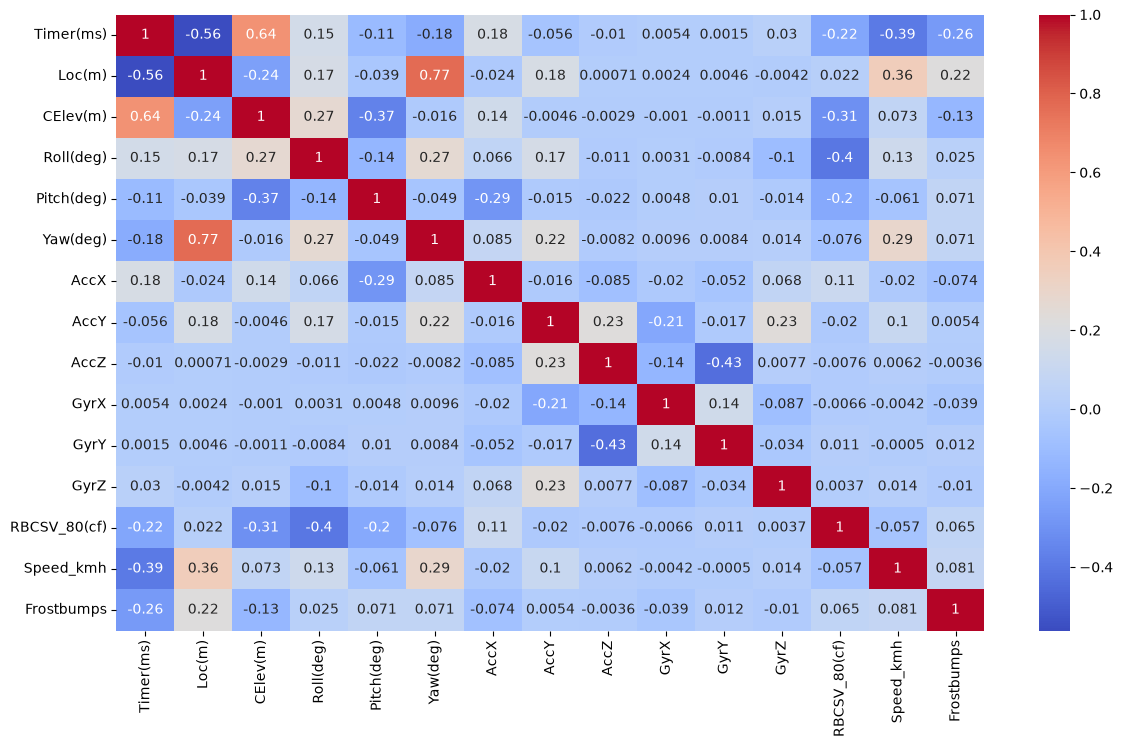

In [26]:
correlatinos = df.corr(numeric_only=True)
plt.figure(figsize=(14,8))
sns.heatmap(correlatinos, annot=True, cmap='coolwarm')

interval columns not set, guessing: ['Timer(ms)', 'Loc(m)', 'CElev(m)', 'Roll(deg)', 'Pitch(deg)', 'Yaw(deg)', 'AccX', 'AccY', 'AccZ', 'GyrX', 'GyrY', 'GyrZ', 'RBCSV_80(cf)', 'Speed_kmh', 'Frostbumps']


<Axes: >

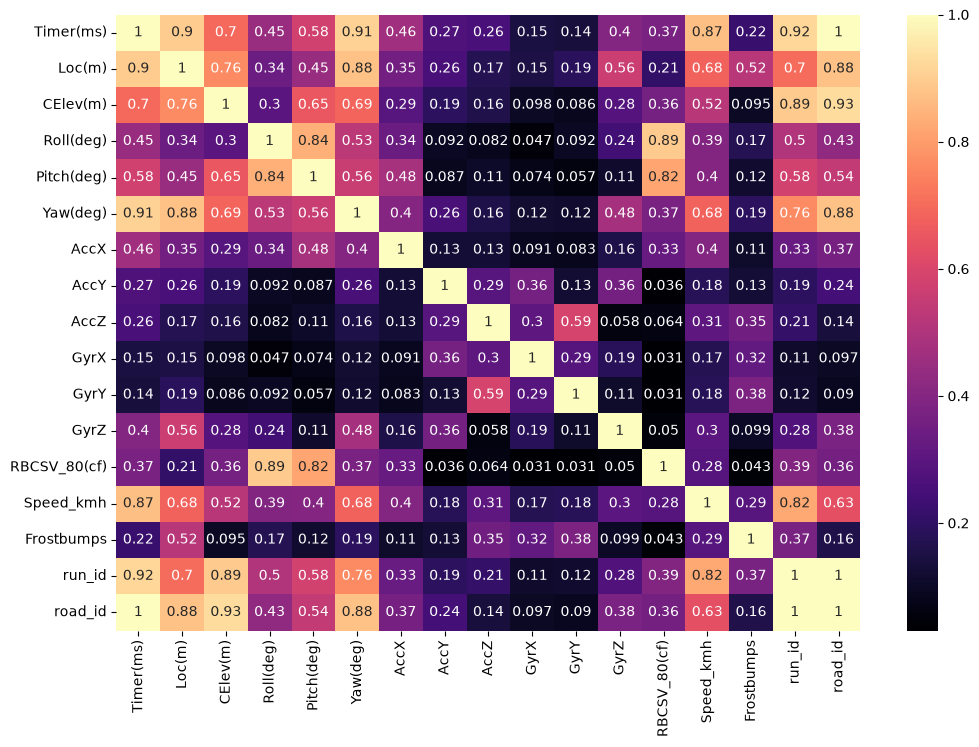

In [27]:
import phik

phik_matrix = df.phik_matrix()

plt.figure(figsize=(12,8))

sns.heatmap(phik_matrix, annot=True, cmap='magma')

In [28]:
feats = ["AccX", "AccY", "AccZ", "GyrX", "GyrY", "GyrZ",
         "Pitch(deg)", "Roll(deg)", "Speed_kmh"]

stats = dfC1.groupby("Frostbumps")[feats].agg(["mean", "std", "min", "median", "max"])
print(stats.T)   # transposed is easier to read

Frostbumps                 0          1
AccX       mean     0.476825   0.320048
           std      0.428491   0.573071
           min     -1.884410  -2.872710
           median   0.473110   0.325095
           max      3.077820   5.295810
AccY       mean     0.040436  -0.002602
           std      0.491550   0.613048
           min     -3.469780  -4.013620
           median   0.058200  -0.008840
           max      3.194060   3.741680
AccZ       mean     9.815373   9.938401
           std      0.709214   1.855630
           min      5.013840   3.221790
           median   9.819500   9.876615
           max     15.227900  24.575690
GyrX       mean    -0.005012  -0.010001
           std      0.029804   0.050709
           min     -0.179980  -0.397290
           median  -0.005130  -0.016745
           max      0.279600   0.139680
GyrY       mean     0.000728  -0.006790
           std      0.033499   0.206710
           min     -0.306870  -0.961550
           median   0.000990  -0.000855


In [29]:
for f in ["AccZ", "GyrY"]:
    df[f + "_abs"] = df[f].abs()

print(df.groupby("Frostbumps")[["AccZ_abs", "GyrY_abs"]].describe().T)

Frostbumps                  0             1
AccZ_abs count  326779.000000  70157.000000
         mean        9.824436      9.813881
         std         0.874910      1.838977
         min         1.498380      1.286240
         25%         9.383040      8.965630
         50%         9.823350      9.812350
         75%        10.263300     10.582790
         max        19.194780     24.575690
GyrY_abs count  326779.000000  70157.000000
         mean        0.023171      0.066332
         std         0.023709      0.076554
         min         0.000000      0.000000
         25%         0.007410      0.017310
         50%         0.016270      0.041830
         75%         0.030810      0.088570
         max         0.325800      0.961550


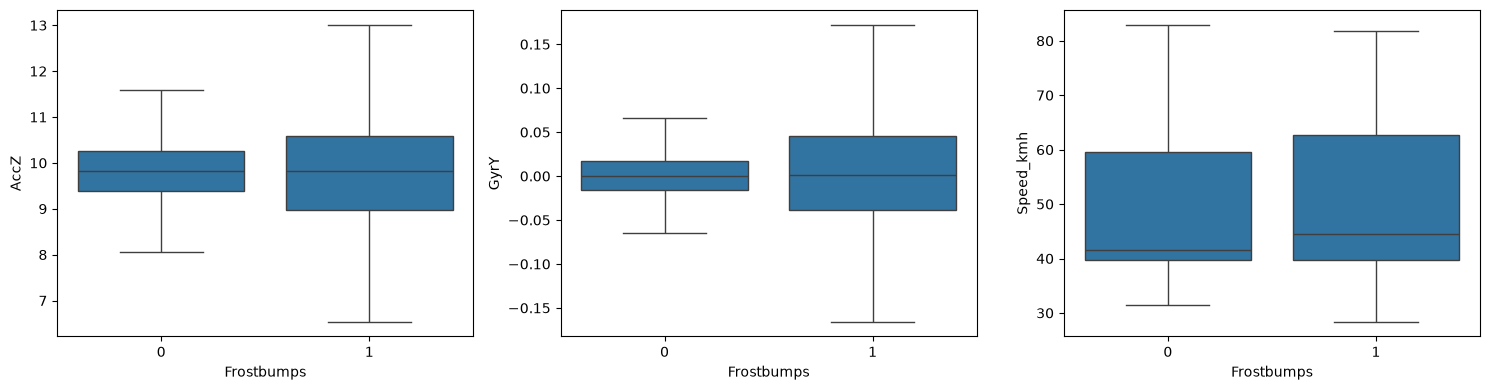

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, f in zip(axes, ["AccZ", "GyrY", "Speed_kmh"]):
    sns.boxplot(data=df, x="Frostbumps", y=f, ax=ax, showfliers=False)
plt.tight_layout()

In [31]:
def bump_events(d):
    flag = d["Frostbumps"].to_numpy()
    edges = np.diff(flag, prepend=0, append=0)
    starts, ends = np.where(edges == 1)[0], np.where(edges == -1)[0]
    rows = []
    for s, e in zip(starts, ends):
        seg = d.iloc[s:e]
        rows.append({
            "run_id": d["run_id"].iloc[0],
            "n_rows": len(seg),
            "length_m": seg["Loc(m)"].iloc[-1] - seg["Loc(m)"].iloc[0],
            "speed": seg["Speed_kmh"].mean(),
            "accz_peak": seg["AccZ"].abs().max(),
            "gyry_peak": seg["GyrY"].abs().max(),
            "accz_rms": np.sqrt((seg["AccZ"]**2).mean()),
        })
    return pd.DataFrame(rows)

events = pd.concat([bump_events(d) for _, d in df.groupby("run_id")], ignore_index=True)
print(events.describe())

            n_rows    length_m      speed  accz_peak  gyry_peak   accz_rms
count    48.000000   48.000000  48.000000  48.000000  48.000000  48.000000
mean   1461.604167   53.650625  55.784735  15.993426   0.295716  10.040141
std     868.273580   29.025974  15.776824   2.853831   0.140082   0.214683
min     256.000000   10.977000  36.424788  11.878940   0.101250   9.789354
25%     756.500000   31.934500  40.156234  13.660113   0.222298   9.875221
50%    1249.000000   51.950500  57.806597  15.778525   0.279550   9.993648
75%    2064.250000   81.948500  70.057622  17.088837   0.357712  10.196399
max    3933.000000  112.976000  81.753203  24.575690   0.961550  10.744820


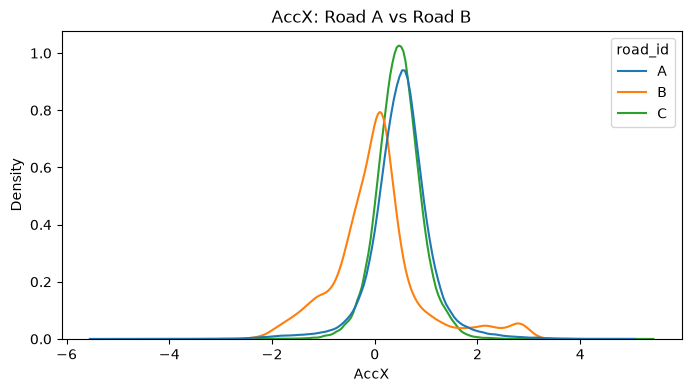

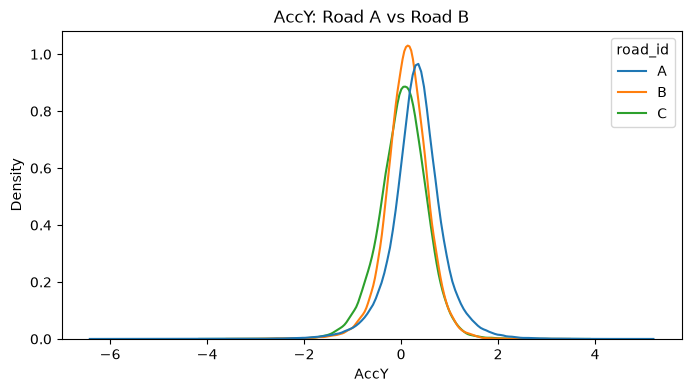

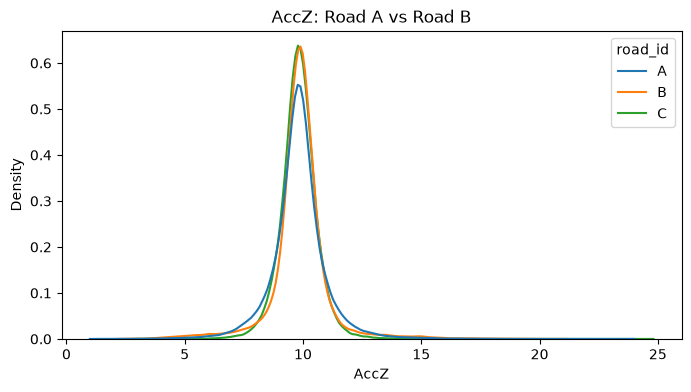

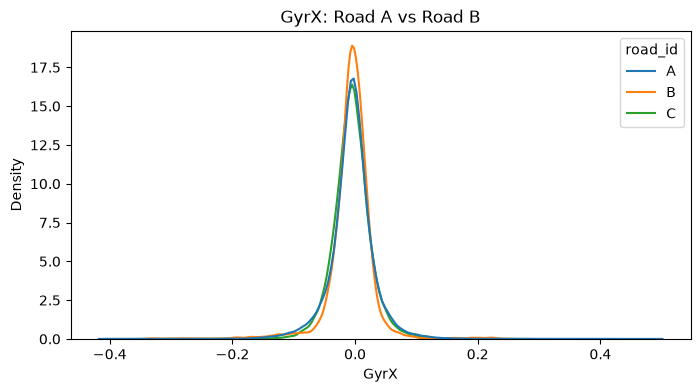

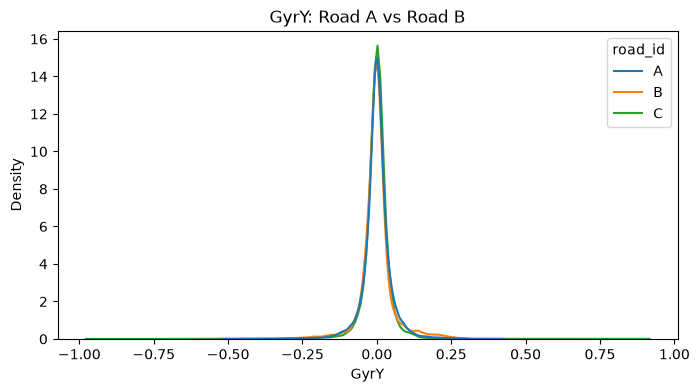

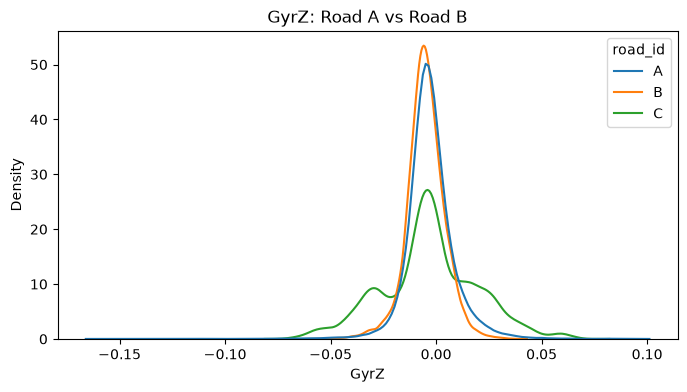

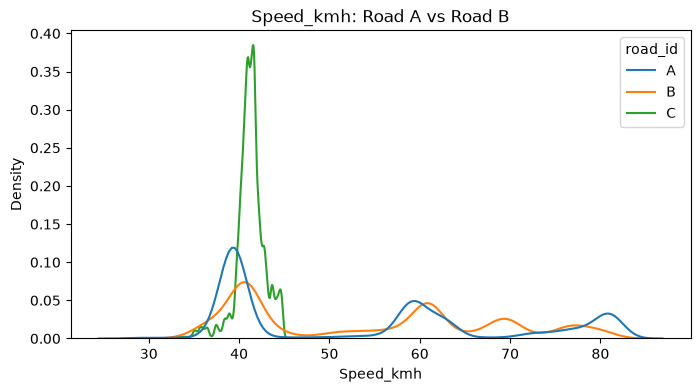

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

features = ["AccX", "AccY", "AccZ", "GyrX", "GyrY", "GyrZ", "Speed_kmh", "RS"]

for feature in features:
    plt.figure(figsize=(8, 4))

    sns.kdeplot(data=df, x=feature, hue="road_id", common_norm=False)

    plt.title(f"{feature}: Road A vs Road B")
    plt.show()

In [33]:
features = [
    "AccX", "AccY", "AccZ",
    "GyrX", "GyrY", "GyrZ",
    "Speed_kmh"
]


comparison = df.groupby(
    ["road_id", "Frostbumps"]
)[features].agg(["mean", "std"])

print(comparison)

                        AccX                AccY                AccZ  \
                        mean       std      mean       std      mean   
road_id Frostbumps                                                     
A       0           0.524779  0.563322  0.334978  0.506320  9.822913   
        1           0.471057  0.727893  0.302907  0.730826  9.787709   
B       0           0.049858  1.107458  0.120433  0.420924  9.875345   
        1           0.042346  0.403207  0.113849  0.491907  9.848386   
C       0           0.476825  0.428491  0.040436  0.491550  9.815373   
        1           0.320048  0.573071 -0.002602  0.613048  9.938401   

                                  GyrX                GyrY            \
                         std      mean       std      mean       std   
road_id Frostbumps                                                     
A       0           0.975427 -0.004449  0.028887  0.000457  0.033248   
        1           1.846627 -0.006857  0.059049  0.003304  0.0